# Cadena de Markov simple: ocupación de las estaciones de Buenavista
**Pregunta:** si una estación está en cierto nivel de ocupación ahora, ¿cómo va a estar en una, dos o tres horas?

- **Clúster:** las 8 estaciones del nodo Buenavista (271, 266, 273, 548, 268, 547, 264, 176). Es el punto con más
  viajes de la ciudad y donde más bicis tiene que mover la operación.
- **Estado:** la ocupación de cada estación, L = bicis / puertos, en 5 niveles.
- **Paso:** una hora. Días hábiles de septiembre (para entrenar) y octubre (para probar).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from datasetting import RUTA_OCTUBRE, FERIADOS, cargar_datos, cargar_capacidades, aplicar_estilo

aplicar_estilo()
FIGS = Path("reporte/figs")
FIGS.mkdir(parents=True, exist_ok=True)

CLUSTER = [271, 266, 273, 548, 268, 547, 264, 176]
ESTADOS = ["Vacía", "Baja", "Media", "Alta", "Llena"]
CORTES = [0.10, 0.35, 0.65, 0.90]          # L < 10 % vacía ... L >= 90 % llena
BLOQUES = {"Mañana (6-11 h)": range(6, 11), "Mediodía (11-16 h)": range(11, 16), "Tarde (16-21 h)": range(16, 21)}
COLORES = ["#e34948", "#eda100", "#1baf7a", "#2a78d6", "#6250d6"]

## 1. Datos
Ecobici no publica cuántas bicis hay en cada estación, solo los viajes. La capacidad (puertos) sí está en su
feed público GBFS (`datasetting.cargar_capacidades`).

In [2]:
viajes_sep, estaciones = cargar_datos(validos=False)
viajes_oct, _ = cargar_datos(validos=False, ruta_viajes=RUTA_OCTUBRE)
viajes = pd.concat([viajes_sep, viajes_oct], ignore_index=True).dropna(subset=["Ciclo_Estacion_Retiro", "Ciclo_Estacion_Arribo"])
capacidad = cargar_capacidades().loc[CLUSTER]
capacidad.index = capacidad.index.astype(int)

pd.DataFrame({"Estación": estaciones.loc[CLUSTER, "Estacion"], "Puertos": capacidad})

,Estación,Puertos
num_cicloe,,
176,Jesus Garcia y Luis Donaldo Colosio,39
264,Heroes Ferrocarrileros y Jesus Garcia,71
266,Jesus Garcia y Carlos J. Meneses,75
268,Luis Donaldo Colosio y Jesus Garcia,69
271,Jesus Garcia y Carlos J. Meneses,74
273,Luis Donaldo Colosio y Jesus Garcia,70
547,Doctor Enrique Gonzalez Martinez y Salvador Di...,31
548,Doctor Mariano Azuela y Jose Antonio Alzate,39


## 2. ¿Cuántas bicis hay en cada estación a cada hora?
Se reconstruye siguiendo a cada bici: si llega a una estación y su siguiente viaje sale de ahí, estuvo anclada
ahí todo ese tiempo. Si su siguiente viaje sale de otra estación, la movió un camión; como no sabemos a qué hora,
suponemos que fue a la mitad del hueco (máximo 2 horas después de llegar / antes de volver a rentarse).

In [3]:
v = viajes.sort_values(["Bici", "Fecha_Hora_Retiro"]).reset_index(drop=True)
v["sig_est"] = v.groupby("Bici")["Ciclo_Estacion_Retiro"].shift(-1)
v["sig_retiro"] = v.groupby("Bici")["Fecha_Hora_Retiro"].shift(-1)
movida = v["sig_est"].notna() & (v["sig_est"] != v["Ciclo_Estacion_Arribo"])
medio = ((v["sig_retiro"] - v["Fecha_Hora_Arribo"]) / 2).clip(upper=pd.Timedelta(hours=2))

inicio = pd.Timestamp("2026-09-01")
cambios = pd.concat([
    pd.DataFrame({"ts": v["Fecha_Hora_Retiro"], "est": v["Ciclo_Estacion_Retiro"], "d": -1}),           # alguien renta
    pd.DataFrame({"ts": v["Fecha_Hora_Arribo"], "est": v["Ciclo_Estacion_Arribo"], "d": +1}),           # alguien devuelve
    pd.DataFrame({"ts": (v["Fecha_Hora_Arribo"] + medio)[movida], "est": v["Ciclo_Estacion_Arribo"][movida], "d": -1}),  # camión saca
    pd.DataFrame({"ts": (v["sig_retiro"] - medio)[movida], "est": v["sig_est"][movida], "d": +1}),        # camión mete
])
# El primer viaje de cada bici: si es el primer día, la bici ya estaba anclada ahí al arrancar;
# si es después (regresa del taller o es nueva), alguien la puso en la estación 2 h antes (como en los camiones)
primero = v.groupby("Bici").head(1)
primero = primero[primero["Fecha_Hora_Retiro"] >= inicio]
al_arranque = primero["Fecha_Hora_Retiro"] < inicio + pd.Timedelta(days=1)
k_inicial = primero.loc[al_arranque, "Ciclo_Estacion_Retiro"].astype(int).value_counts().reindex(CLUSTER, fill_value=0)
llegan_despues = primero[~al_arranque]
cambios = pd.concat([cambios, pd.DataFrame({"ts": llegan_despues["Fecha_Hora_Retiro"] - pd.Timedelta(hours=2),
                                            "est": llegan_despues["Ciclo_Estacion_Retiro"], "d": +1})])
cambios = cambios[cambios["est"].isin(CLUSTER) & (cambios["ts"] >= inicio)].astype({"est": int})

# Inventario al inicio de cada hora
cambios["hora"] = cambios["ts"].dt.floor("h")
neto_hora = cambios.groupby(["hora", "est"])["d"].sum().unstack(fill_value=0).reindex(columns=CLUSTER, fill_value=0)
horas = pd.date_range(inicio, "2026-11-01", freq="h")
neto_hora = neto_hora.reindex(horas, fill_value=0)
bicis = neto_hora.cumsum().shift(1, fill_value=0) + k_inicial      # bicis presentes justo al empezar cada hora
ocupacion = (bicis / capacidad).clip(0, 1)

print(f"Horas con inventario negativo: {(bicis < 0).values.mean():.2%} | por encima de la capacidad: {(bicis > capacidad).values.mean():.2%}")
print("% de horas por encima de la capacidad, por estación:", (bicis > capacidad).mean().mul(100).round(1).to_dict())

Horas con inventario negativo: 0.00% | por encima de la capacidad: 5.38%
% de horas por encima de la capacidad, por estación: {271: 21.0, 266: 9.6, 273: 2.5, 548: 6.3, 268: 0.0, 547: 3.1, 264: 0.0, 176: 0.5}


La reconstrucción nunca da bicis negativas. Pasarse de la capacidad ocurre en ~5 % de las horas, casi siempre en las
estaciones grandes de Buenavista en la tarde: en el pico llegan más bicis de las que caben y el personal/camiones
las van sacando, pero no sabemos la hora exacta. Para el modelo la ocupación se recorta a [0, 1] (cuenta como Llena).

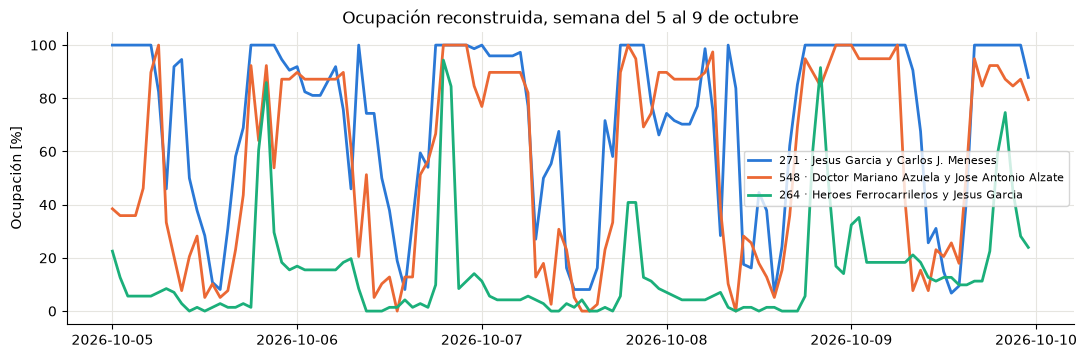

In [4]:
fig, ax = plt.subplots(figsize=(13, 3.8))
semana = ocupacion.loc["2026-10-05":"2026-10-09 23:00"]
for est in [271, 548, 264]:
    ax.plot(semana.index, semana[est] * 100, label=f"{est} · {estaciones.loc[est, 'Estacion']}")
ax.set(title="Ocupación reconstruida, semana del 5 al 9 de octubre", ylabel="Ocupación [%]")
ax.legend(fontsize=8)
fig.savefig(FIGS / "01_ocupacion_semana.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Estados
Cada estación, en cada hora, cae en uno de 5 niveles.

In [5]:
estado = pd.DataFrame(np.digitize(ocupacion, CORTES), index=ocupacion.index, columns=CLUSTER)
pd.DataFrame({"Estado": ESTADOS,
              "Ocupación": ["menos de 10 %", "10–35 %", "35–65 %", "65–90 %", "90 % o más"]})

,Estado,Ocupación
0,Vacía,menos de 10 %
1,Baja,10–35 %
2,Media,35–65 %
3,Alta,65–90 %
4,Llena,90 % o más


In [6]:
# Días útiles: entre semana, sin el feriado del 16-sep y sin días con alguna estación del clúster apagada
uso_dia = cambios.groupby([cambios["ts"].dt.normalize(), "est"]).size().unstack(fill_value=0).reindex(columns=CLUSTER, fill_value=0)
dias = pd.date_range(inicio, "2026-10-31")
dias = dias[(dias.day_of_week < 5) & ~dias.isin(pd.to_datetime(FERIADOS))]
apagado = (uso_dia.reindex(dias, fill_value=0) <= 2).any(axis=1)
dias = dias[~apagado.to_numpy()]
print(f"Días hábiles útiles: {len(dias)} ({(dias.month == 9).sum()} de septiembre, {(dias.month == 10).sum()} de octubre)")
print("Quitados por estación apagada:", [f"{d:%d-%b}" for d in apagado[apagado].index])

Días hábiles útiles: 41 (19 de septiembre, 22 de octubre)
Quitados por estación apagada: ['14-Sep', '15-Sep']


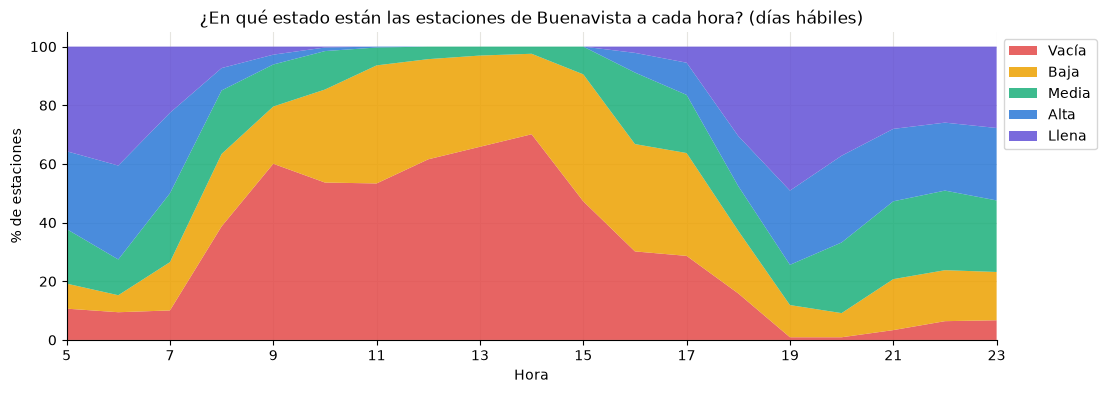

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
habiles = estado[estado.index.normalize().isin(dias)]
por_hora = (habiles.stack().groupby([habiles.stack().index.get_level_values(0).hour, habiles.stack().values]).size()
            .unstack(fill_value=0).reindex(columns=range(5), fill_value=0))
por_hora = por_hora.div(por_hora.sum(axis=1), axis=0).loc[5:23] * 100
ax.stackplot(por_hora.index, por_hora.T, labels=ESTADOS, colors=COLORES, alpha=0.85)
ax.set(title="¿En qué estado están las estaciones de Buenavista a cada hora? (días hábiles)",
       xlabel="Hora", ylabel="% de estaciones", xlim=(5, 23), xticks=range(5, 24, 2))
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(FIGS / "02_estados_por_hora.png", dpi=130, bbox_inches="tight")
plt.show()

En la mañana las estaciones se vacían (la gente sale de Buenavista en bici) y desde media tarde se llenan
(la gente regresa al tren). Por eso no basta una sola matriz: se estima una por bloque del día.

## 4. La cadena de Markov
Para cada bloque se cuentan los cambios de estado de una hora a la siguiente (juntando las 8 estaciones) y se
divide cada fila entre su total: P[i, j] = probabilidad de pasar del estado i al j en una hora.

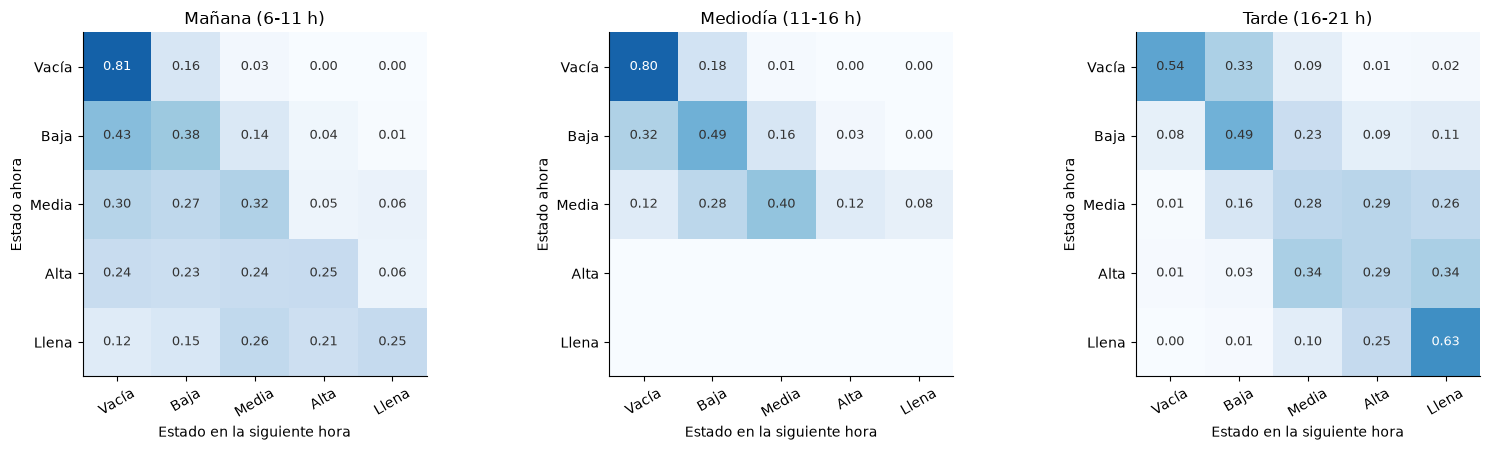

In [8]:
def matriz_transicion(dias_, horas_bloque):
    conteo = np.zeros((5, 5))
    for d in dias_:
        for h in horas_bloque:
            ahora, despues = estado.loc[d + pd.Timedelta(hours=h)], estado.loc[d + pd.Timedelta(hours=h + 1)]
            np.add.at(conteo, (ahora.to_numpy(), despues.to_numpy()), 1)
    P = conteo / np.maximum(conteo.sum(axis=1, keepdims=True), 1)
    return pd.DataFrame(P, index=ESTADOS, columns=ESTADOS), pd.DataFrame(conteo, index=ESTADOS, columns=ESTADOS).astype(int)


dias_sep, dias_oct = dias[dias.month == 9], dias[dias.month == 10]
P = {b: matriz_transicion(dias_sep, h)[0] for b, h in BLOQUES.items()}       # entrenadas con septiembre
conteos = {b: matriz_transicion(dias_sep, h)[1] for b, h in BLOQUES.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (b, M) in zip(axes, P.items()):
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            if conteos[b].iloc[i].sum() > 0:
                ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if M.iloc[i, j] > 0.55 else "#333")
    ax.set_xticks(range(5), ESTADOS, rotation=30)
    ax.set_yticks(range(5), ESTADOS)
    ax.grid(False)
    ax.set(title=b, xlabel="Estado en la siguiente hora", ylabel="Estado ahora")
plt.tight_layout()
fig.savefig(FIGS / "03_matrices.png", dpi=130, bbox_inches="tight")
plt.show()

In [9]:
for b in BLOQUES:
    print(b, "— observaciones por estado de partida:", conteos[b].sum(axis=1).to_dict())

Mañana (6-11 h) — observaciones por estado de partida: {'Vacía': 298, 'Baja': 132, 'Media': 144, 'Alta': 102, 'Llena': 84}
Mediodía (11-16 h) — observaciones por estado de partida: {'Vacía': 537, 'Baja': 198, 'Media': 25, 'Alta': 0, 'Llena': 0}
Tarde (16-21 h) — observaciones por estado de partida: {'Vacía': 148, 'Baja': 189, 'Media': 141, 'Alta': 110, 'Llena': 172}


Cómo leer una fila: en la tarde, una estación que está **Alta** a las 17:00 tiene la probabilidad de la celda
(Alta, Llena) de estar llena a las 18:00. La diagonal es la probabilidad de quedarse igual.

## 5. ¿Sirve para predecir? (entrenada con septiembre, probada con octubre)
Se compara contra la predicción más ingenua posible: "en una hora va a estar igual que ahora".

In [10]:
def evaluar(dias_, b, horizonte):
    aciertos_markov = aciertos_ingenuo = n = 0
    log_verosimilitud = 0.0
    Pn = np.linalg.matrix_power(P[b].to_numpy(), horizonte)
    for d in dias_:
        for h in BLOQUES[b]:
            if h + horizonte > max(BLOQUES[b]) + 1:
                continue
            ahora = estado.loc[d + pd.Timedelta(hours=h)].to_numpy()
            despues = estado.loc[d + pd.Timedelta(hours=h + horizonte)].to_numpy()
            aciertos_markov += (Pn[ahora].argmax(axis=1) == despues).sum()
            aciertos_ingenuo += (ahora == despues).sum()
            log_verosimilitud += np.log(np.maximum(Pn[ahora, despues], 1e-3)).sum()
            n += len(ahora)
    return {"Bloque": b, "Horizonte (h)": horizonte, "Predicciones": n,
            "Acierto Markov": aciertos_markov / n, "Acierto 'igual que ahora'": aciertos_ingenuo / n,
            "Prob. media asignada a lo que pasó": np.exp(log_verosimilitud / n)}


evaluacion = pd.DataFrame([evaluar(dias_oct, b, hz) for b in BLOQUES for hz in [1, 2, 3]])
evaluacion.round(3)

,Bloque,Horizonte (h),Predicciones,Acierto Markov,Acierto 'igual que ahora',Prob. media asignada a lo que pasó
0,Mañana (6-11 h),1,880,0.427,0.515,0.322
1,Mañana (6-11 h),2,704,0.453,0.328,0.311
2,Mañana (6-11 h),3,528,0.502,0.229,0.331
3,Mediodía (11-16 h),1,880,0.659,0.659,0.418
4,Mediodía (11-16 h),2,704,0.453,0.561,0.331
5,Mediodía (11-16 h),3,528,0.398,0.534,0.288
6,Tarde (16-21 h),1,880,0.411,0.477,0.292
7,Tarde (16-21 h),2,704,0.334,0.283,0.245
8,Tarde (16-21 h),3,528,0.381,0.216,0.251


- A **1 hora**, "igual que ahora" gana o empata: en una hora casi todo se queda en su estado.
- A **2–3 horas**, en la mañana y en la tarde la cadena acierta bastante más (≈ 45–50 % vs 22–33 %), porque
  sabe hacia dónde se mueven las estaciones (se vacían en la mañana, se llenan en la tarde). Ese es el horizonte
  útil para mandar un camión con tiempo.
- Al **mediodía** no gana: las estaciones se quedan vacías horas y la persistencia es la mejor predicción.
- Aciertos de 40–50 % con 5 estados no es "perfecto", pero el azar daría 20 %. La cadena se entrenó con
  septiembre y se probó con octubre, así que lo aprendido sí se sostiene de un mes a otro.

## 6. Lo que la cadena dice para operar
### 6.1 Arrancando a las 16:00, ¿cómo van a estar las estaciones a las 17, 18, 19 y 20 h?

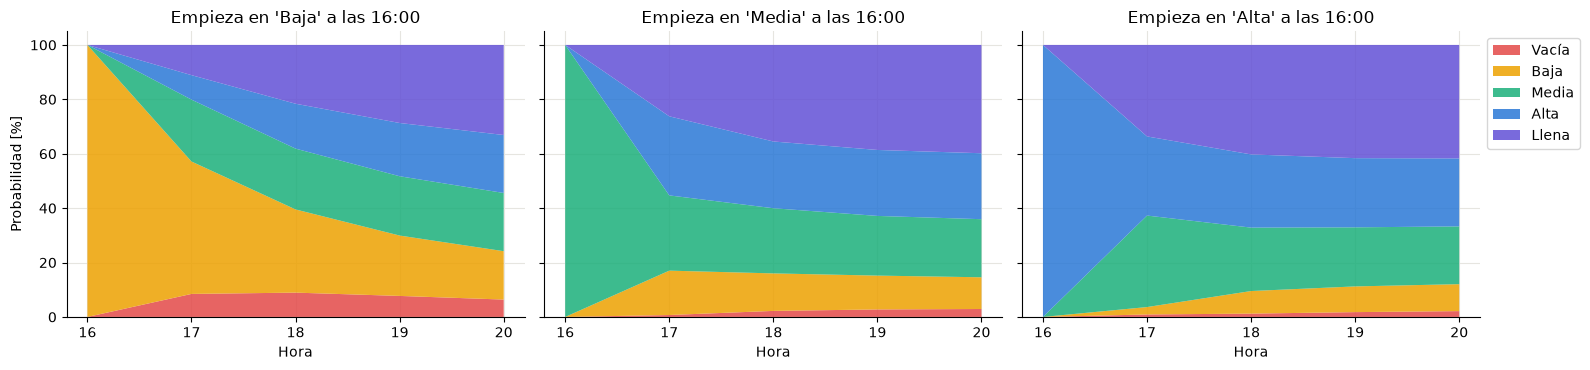

In [11]:
Pt = P["Tarde (16-21 h)"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, inicio_estado in zip(axes, [1, 2, 3]):
    dist = np.eye(5)[inicio_estado]
    trayecto = [dist]
    for _ in range(4):
        dist = dist @ Pt
        trayecto.append(dist)
    trayecto = np.array(trayecto) * 100
    ax.stackplot(range(16, 21), trayecto.T, colors=COLORES, alpha=0.85, labels=ESTADOS)
    ax.set(title=f"Empieza en '{ESTADOS[inicio_estado]}' a las 16:00", xlabel="Hora", xticks=range(16, 21))
axes[0].set_ylabel("Probabilidad [%]")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
fig.savefig(FIGS / "04_pronostico_tarde.png", dpi=130, bbox_inches="tight")
plt.show()

### 6.2 Riesgo de quedar llena o vacía en las próximas 1, 2 y 3 horas
Probabilidad de estar **Llena** (tarde) o **Vacía** (mañana) dentro de n horas según el estado de ahora.

In [12]:
riesgo = []
for b, critico in [("Tarde (16-21 h)", 4), ("Mañana (6-11 h)", 0)]:
    M = P[b].to_numpy()
    for n in [1, 2, 3]:
        Pn = np.linalg.matrix_power(M, n)
        riesgo.append({"Bloque": b, "Riesgo": f"P(estar {ESTADOS[critico]})", "En (h)": n,
                       **{f"si ahora está {e}": Pn[i, critico] for i, e in enumerate(ESTADOS)}})
pd.DataFrame(riesgo).round(2)

,Bloque,Riesgo,En (h),si ahora está Vacía,si ahora está Baja,si ahora está Media,si ahora está Alta,si ahora está Llena
0,Tarde (16-21 h),P(estar Llena),1,0.02,0.11,0.26,0.34,0.63
1,Tarde (16-21 h),P(estar Llena),2,0.09,0.22,0.35,0.40,0.51
2,Tarde (16-21 h),P(estar Llena),3,0.17,0.29,0.39,0.42,0.47
3,Mañana (6-11 h),P(estar Vacía),1,0.81,0.43,0.30,0.24,0.12
4,Mañana (6-11 h),P(estar Vacía),2,0.74,0.57,0.47,0.42,0.32
5,Mañana (6-11 h),P(estar Vacía),3,0.70,0.62,0.57,0.54,0.47


### 6.3 ¿Cuántas horas tarda en llenarse una estación en la tarde?
Tiempo medio hasta llegar a "Llena" desde cada estado, suponiendo que la tarde (matriz de 16–21 h) siguiera así.
Sale de resolver t = 1 + P·t para los estados no llenos.

In [13]:
def horas_hasta(M, objetivo):
    otros = [i for i in range(5) if i != objetivo]
    Q = M[np.ix_(otros, otros)]
    t = np.linalg.solve(np.eye(len(otros)) - Q, np.ones(len(otros)))
    return pd.Series(t, index=[ESTADOS[i] for i in otros])


pd.DataFrame({"Horas hasta Llena (tarde)": horas_hasta(Pt, 4),
              "Horas hasta Vacía (mañana)": horas_hasta(P["Mañana (6-11 h)"].to_numpy(), 0)}).reindex(ESTADOS).round(1)

,Horas hasta Llena (tarde),Horas hasta Vacía (mañana)
Vacía,7.2,NaN
Baja,5.7,2.6
Media,4.2,3.1
Alta,3.7,3.4
Llena,NaN,3.9


### 6.4 ¿Qué estaciones se llevan el problema?
Fracción de las horas de cada bloque en que cada estación estuvo Llena o Vacía (días hábiles de octubre).

In [14]:
filas = {}
for b, hs in BLOQUES.items():
    sel = estado[estado.index.normalize().isin(dias_oct) & estado.index.hour.isin(hs)]
    filas[(b, "% horas Vacía")] = (sel == 0).mean() * 100
    filas[(b, "% horas Llena")] = (sel == 4).mean() * 100
por_estacion = pd.DataFrame(filas).round(0)
por_estacion.insert(0, ("", "Estación"),estaciones.loc[CLUSTER, "Estacion"].str.slice(0, 32))
por_estacion

Mañana (6-11 h)                \
                             Estación   % horas Vacía % horas Llena   
271  Jesus Garcia y Carlos J. Meneses             8.0          10.0   
266  Jesus Garcia y Carlos J. Meneses            21.0          27.0   
273  Luis Donaldo Colosio y Jesus Gar            14.0          35.0   
548  Doctor Mariano Azuela y Jose Ant            16.0          14.0   
268  Luis Donaldo Colosio y Jesus Gar            44.0          16.0   
547  Doctor Enrique Gonzalez Martinez            27.0          17.0   
264  Heroes Ferrocarrileros y Jesus G            77.0           0.0   
176  Jesus Garcia y Luis Donaldo Colo            35.0          23.0   

    Mediodía (11-16 h)               Tarde (16-21 h)                
         % horas Vacía % horas Llena   % horas Vacía % horas Llena  
271               26.0           0.0             0.0          68.0  
266               46.0           0.0             0.0          29.0  
273               31.0           0.0             2.0          21.0  
548               25.0           0.0             0.0          35.0  
268               82.0           0.0            21.0          18.0  
547               49.0           0.0             4.0          20.0  
264               91.0           0.0            53.0           5.0  
176               51.0           0.0            15.0          18.0

### 6.5 Una cuenta rápida de camiones
Si cada hora la cadena dice cuántas de las 8 estaciones van a terminar llenas o vacías, eso es cuántas
visitas de camión hacen falta por hora para evitarlo. (Las 49 unidades de Ecobici son para toda la ciudad;
esto es solo lo que pediría este clúster.)

In [15]:
visitas = {}
for b, hs in BLOQUES.items():
    M = P[b].to_numpy()
    critico = [0, 4]
    sel = estado[estado.index.normalize().isin(dias_oct) & estado.index.hour.isin(hs)]
    # Por cada estación-hora no crítica, la probabilidad de volverse crítica en la siguiente hora
    prob = M[:, critico].sum(axis=1)
    nuevas = np.mean([prob[fila[~np.isin(fila, critico)]].sum() for fila in sel.to_numpy()])
    ya = np.isin(sel.to_numpy(), critico).sum(axis=1).mean()
    visitas[b] = {"Estaciones ya críticas (promedio por hora)": ya, "Nuevas críticas esperadas por hora": nuevas}
visitas = pd.DataFrame(visitas).T
visitas["Visitas por hora para atender las nuevas"] = np.ceil(visitas["Nuevas críticas esperadas por hora"])
visitas.round(2)

,Estaciones ya críticas (promedio por hora),Nuevas críticas esperadas por hora,Visitas por hora para atender las nuevas
Mañana (6-11 h),3.85,1.55,2.0
Mediodía (11-16 h),4.01,1.22,2.0
Tarde (16-21 h),3.08,1.33,2.0


Un camión que va, carga ~20 bicis y regresa tarda del orden de 15–25 minutos, así que hace 2–4 visitas por hora.
Con eso, **1 camión dedicado** alcanza para ir atendiendo las nuevas estaciones críticas que va generando el clúster;
un **segundo camión** en la tarde serviría para bajar las que ya están llenas (sobre todo la 271 y la 266, que
pasan buena parte de la tarde llenas).

## 7. Estado de largo plazo de cada bloque
Si las condiciones de un bloque durasen indefinidamente, la cadena terminaría en esta distribución
(vector π con π = π·P). Sirve para resumir hacia dónde "empuja" cada bloque a las estaciones.

In [16]:
def estacionaria(M):
    valores, vectores = np.linalg.eig(M.T)
    pi = np.real(vectores[:, np.argmin(np.abs(valores - 1))])
    return pi / pi.sum()


pd.DataFrame({b: estacionaria(M.to_numpy()) for b, M in P.items()}, index=ESTADOS).mul(100).round(1)

,Mañana (6-11 h),Mediodía (11-16 h),Tarde (16-21 h)
Vacía,66.6,59.9,2.8
Baja,21.7,28.2,10.7
Media,8.4,9.3,21.0
Alta,2.2,1.9,24.5
Llena,1.1,0.8,41.0
